# 02 – Distributions and Outliers

**Objective:** analyse the distribution of the target (`price`) and of the main numerical and categorical features, detect outliers and erroneous extreme values, and decide how to treat them before modelling.

**Input:** `data/processed/listings_00.parquet` (output of notebook 00).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

df = pd.read_parquet("../data/processed/listings_00.parquet")
df.shape

(23109, 78)

In [2]:
main_num_cols = ["price", "accommodates", "bedrooms", "beds", "bathrooms",
                 "minimum_nights", "maximum_nights", "number_of_reviews",
                 "review_scores_rating", "availability_365"]

df[main_num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
price,18785.0,208.632525,543.628283,9.13,95.45,151.00,224.50,36883.0
accommodates,23109.0,3.256913,1.934129,1.00,2.00,3.00,4.00,16.0
bedrooms,23097.0,1.396848,1.031847,0.00,1.00,1.00,2.00,50.0
beds,22535.0,2.039405,2.065032,1.00,1.00,2.00,2.00,167.0
bathrooms,23091.0,1.307479,0.741310,0.00,1.00,1.00,1.50,19.0
minimum_nights,21380.0,8.873901,26.244603,1.00,1.00,2.00,5.00,1125.0
maximum_nights,21380.0,585.105519,424.502033,1.00,365.00,365.00,1125.00,11111.0
number_of_reviews,23109.0,65.981436,111.763542,0.00,2.00,22.00,80.00,1600.0
review_scores_rating,19294.0,4.640686,0.480326,0.00,4.55,4.75,4.91,5.0
availability_365,23109.0,159.547319,136.263132,0.00,1.00,151.00,298.00,365.0


## 1. Target variable: `price`

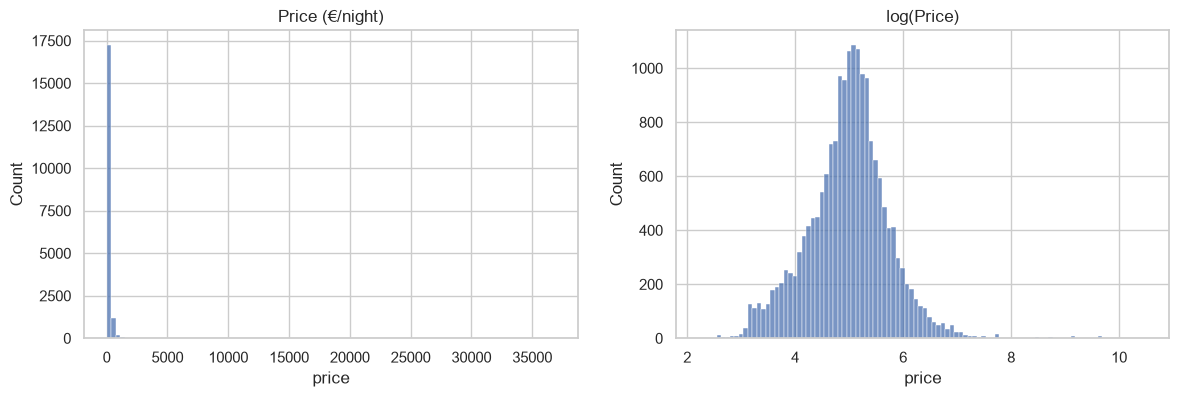

Skewness price:      31.54
Skewness log(price): 0.21


In [3]:
price = df["price"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(price, bins=100, ax=axes[0])
axes[0].set_title("Price (€/night)")
sns.histplot(np.log(price), bins=100, ax=axes[1])
axes[1].set_title("log(Price)")
plt.show()

print(f"Skewness price:      {price.skew():.2f}")
print(f"Skewness log(price): {np.log(price).skew():.2f}")

The raw price is extremely right-skewed (skewness ≈ 31.5): most listings cost less than 250 €/night, but a few reach tens of thousands. After a log transformation the distribution becomes almost symmetric (skewness ≈ 0.2). **Conclusion:** the model should predict `log(price)` instead of `price`, and outliers should be evaluated on the log scale.

In [4]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

low, high = iqr_bounds(price)
n_out = ((price < low) | (price > high)).sum()
print(f"IQR on price:      [{low:.1f}, {high:.1f}] €  -> {n_out} outliers ({n_out/len(price):.1%})")

log_price = np.log(price)
log_low, log_high = iqr_bounds(log_price)
n_out_log = ((log_price < log_low) | (log_price > log_high)).sum()
print(f"IQR on log(price): [{np.exp(log_low):.1f}, {np.exp(log_high):.1f}] €  -> {n_out_log} outliers ({n_out_log/len(price):.1%})")

IQR on price:      [-98.1, 418.1] €  -> 1219 outliers (6.5%)
IQR on log(price): [26.5, 809.8] €  -> 609 outliers (3.2%)


In [5]:
extreme = df[df["price"] >= 5000]
print(f"{len(extreme)} listings with price >= 5,000 €/night")
print(extreme["host_id"].value_counts().head(3))

extreme[["price", "host_id", "room_type", "accommodates",
         "number_of_reviews", "availability_365"]].sort_values("price", ascending=False)

28 listings with price >= 5,000 €/night
host_id
17011402     11
712177646    10
137289804     1
Name: count, dtype: int64


,price,host_id,room_type,accommodates,number_of_reviews,availability_365
6046,36883.00,17011402,Entire home/apt,6,2,351
17978,15000.00,712177646,Entire home/apt,4,0,365
18025,15000.00,712177646,Entire home/apt,4,0,365
18024,15000.00,712177646,Entire home/apt,3,0,365
17986,15000.00,712177646,Private room,2,0,364
17983,15000.00,712177646,Private room,3,0,365
17981,15000.00,712177646,Private room,2,0,365
17980,15000.00,712177646,Private room,2,0,365
17979,15000.00,712177646,Entire home/apt,4,0,365
17827,15000.00,712177646,Entire home/apt,7,0,365


In [6]:
log_low3, log_high3 = iqr_bounds(log_price, k=3)
upper_price = np.exp(log_high3)
print(f"Extreme-outlier threshold (3·IQR on log scale): {upper_price:.0f} €/night")

n_before = len(df)
df = df[~(df["price"] > upper_price)]
print(f"Removed {n_before - len(df)} listings with price > {upper_price:.0f} €/night")
df.shape

Extreme-outlier threshold (3·IQR on log scale): 2921 €/night
Removed 38 listings with price > 2921 €/night


(23071, 78)

### Decision on price outliers

- **Extreme values are errors, not luxury listings.** The 28 listings above 5,000 €/night are mostly ordinary flats and private rooms; 21 of them belong to just two hosts (one with 11 listings at exactly 15,000 €), almost none have reviews and most are available all year. These look like placeholder prices used to block bookings.
- **Action 1 – remove extreme outliers:** listings above the extreme-outlier fence (Q3 + 3·IQR on the log scale ≈ 2,921 €/night) are removed: **38 listings (0.2% of priced listings)**. This is an objective rule, not an arbitrary cut-off.
- **Action 2 – keep moderate outliers:** the 1.5·IQR rule on the log scale flags 609 listings (26.5–810 €/night), mostly cheap private/shared rooms and large or luxury flats. These are plausible prices and represent real market segments, so they are kept. Modelling `log(price)` will limit their influence.
- Applying the IQR rule to the raw price is not appropriate: it flags 6.5% of listings and gives a negative lower bound.

## 2. Main numerical features

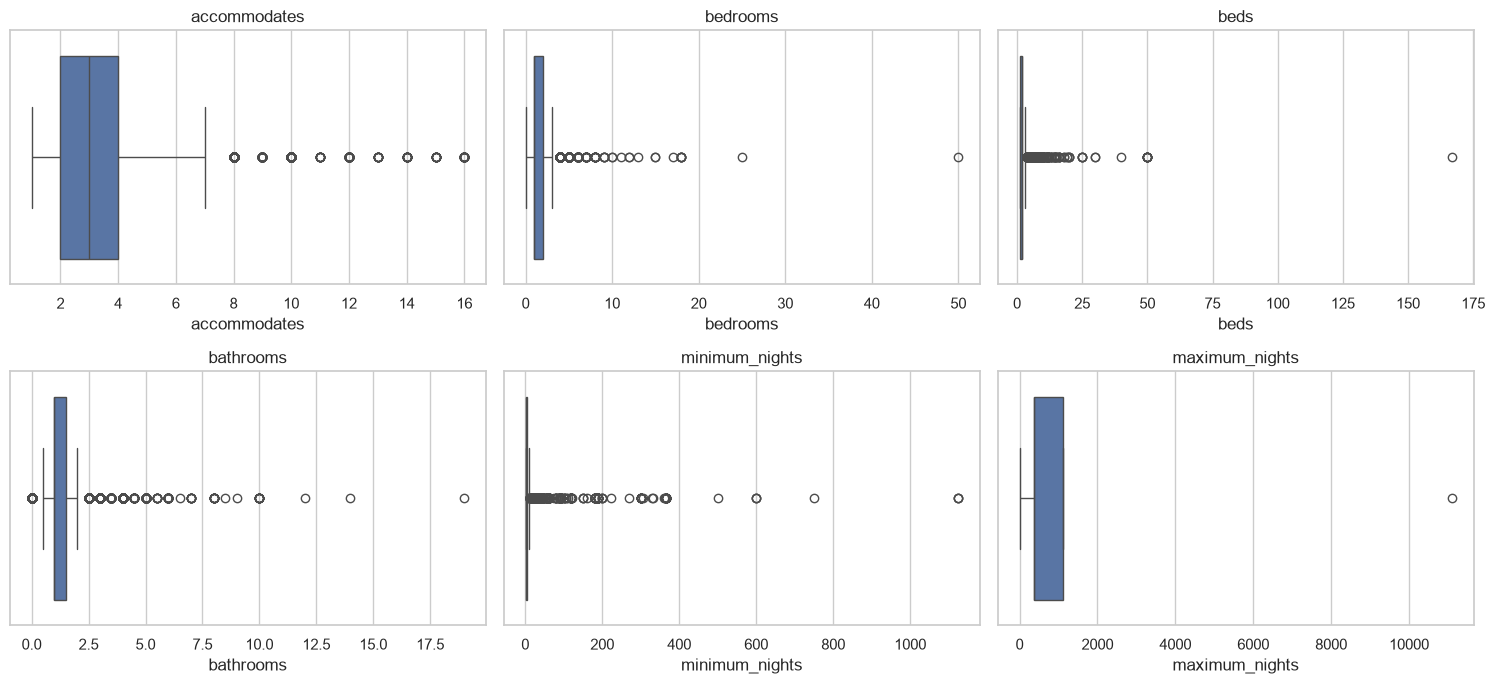

In [7]:
feat_cols = ["accommodates", "bedrooms", "beds", "bathrooms", "minimum_nights", "maximum_nights"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), feat_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [8]:
inconsistent = (df["bedrooms"] > df["accommodates"]) | (df["beds"] > 2 * df["accommodates"])
print(f"{inconsistent.sum()} listings with more bedrooms than guests or more than 2 beds per guest")
print(df.loc[inconsistent, "room_type"].value_counts())

df.loc[inconsistent, ["property_type", "room_type", "accommodates", "bedrooms", "beds", "bathrooms"]] \
  .sort_values("bedrooms", ascending=False).head(10)

236 listings with more bedrooms than guests or more than 2 beds per guest
room_type
Private room       200
Shared room         25
Entire home/apt     11
Name: count, dtype: int64


,property_type,room_type,accommodates,bedrooms,beds,bathrooms
21377,Room in hotel,Private room,1,50.0,1.0,1.0
5762,Private room in hostel,Private room,6,25.0,167.0,1.0
14761,Room in hotel,Private room,2,18.0,25.0,14.0
5457,Room in boutique hotel,Private room,2,18.0,1.0,1.5
14767,Room in hotel,Private room,2,18.0,25.0,1.0
14769,Room in hotel,Private room,1,18.0,25.0,2.0
14768,Room in hotel,Private room,2,18.0,25.0,2.0
21766,Room in boutique hotel,Private room,2,17.0,16.0,1.0
21511,Private room in chalet,Private room,2,15.0,1.0,1.0
1037,Private room in rental unit,Private room,1,13.0,1.0,1.0


In [9]:
caps = df[["bedrooms", "beds", "bathrooms"]].quantile(0.99)
above_cap = (df["bedrooms"] > caps["bedrooms"]) | (df["beds"] > caps["beds"]) | (df["bathrooms"] > caps["bathrooms"])

print(f"{above_cap.sum()} listings above the 99th percentile in bedrooms, beds or bathrooms")
print(df.loc[above_cap, "room_type"].value_counts())

df.loc[above_cap & (df["room_type"] == "Entire home/apt"),
       ["property_type", "accommodates", "bedrooms", "beds", "bathrooms", "price"]].head(10)

381 listings above the 99th percentile in bedrooms, beds or bathrooms
room_type
Entire home/apt    203
Private room       144
Shared room         34
Name: count, dtype: int64


,property_type,accommodates,bedrooms,beds,bathrooms,price
97,Entire rental unit,10,3.0,8.0,1.0,151.21
388,Entire rental unit,12,5.0,7.0,5.5,541.00
457,Entire rental unit,10,3.0,9.0,2.0,201.73
836,Entire home,16,8.0,10.0,5.5,1072.00
928,Entire serviced apartment,8,3.0,9.0,2.0,419.00
1028,Entire rental unit,15,5.0,10.0,2.0,377.00
1092,Entire rental unit,14,4.0,8.0,2.0,501.50
1134,Entire rental unit,9,4.0,8.0,1.0,1660.42
1135,Entire rental unit,9,4.0,8.0,1.0,1736.87
1152,Entire rental unit,16,7.0,13.0,4.5,700.00


In [10]:
df.loc[df["minimum_nights"] > 365,
       ["property_type", "room_type", "minimum_nights", "maximum_nights",
        "price", "number_of_reviews", "availability_365"]]

,property_type,room_type,minimum_nights,maximum_nights,price,number_of_reviews,availability_365
927,Entire condo,Entire home/apt,750.0,1125.0,NaN,182,365
1501,Entire rental unit,Entire home/apt,500.0,1125.0,NaN,20,364
1702,Private room in rental unit,Private room,600.0,1125.0,NaN,197,270
1791,Private room in rental unit,Private room,1125.0,1125.0,NaN,59,270
2322,Private room in home,Private room,600.0,1125.0,NaN,24,90
2549,Private room in home,Private room,600.0,1125.0,NaN,18,0
3788,Entire home,Entire home/apt,1125.0,1125.0,NaN,0,89
4121,Private room in condo,Private room,1125.0,1125.0,NaN,0,363


In [11]:
df["maximum_nights"].value_counts().head(10)

maximum_nights
365.0     7901
1125.0    6646
999.0     1021
30.0       574
125.0      439
330.0      390
90.0       354
7.0        267
60.0       252
180.0      244
Name: count, dtype: int64

In [12]:
size_cols = ["bedrooms", "beds", "bathrooms"]

rooms_inconsistent = inconsistent & (df["room_type"] != "Entire home/apt")
df.loc[rooms_inconsistent, size_cols] = np.nan
print(f"Size features set to NaN in {rooms_inconsistent.sum()} inconsistent rooms")
print(f"Inconsistent entire homes kept as they are: {(inconsistent & ~rooms_inconsistent).sum()}")
print(df[size_cols].describe().T[["count", "max"]])

df["long_stay"] = df["minimum_nights"] >= 30
print(f"\nListings with minimum stay >= 30 nights: {df['long_stay'].mean():.1%}")
print(df.groupby("long_stay")["price"].agg(["count", "median"]))
df.shape

Size features set to NaN in 225 inconsistent rooms
Inconsistent entire homes kept as they are: 11
             count   max
bedrooms   22834.0  15.0
beds       22275.0  20.0
bathrooms  22829.0   9.0

Listings with minimum stay >= 30 nights: 13.7%
           count   median
long_stay                
False      16423  159.000
True        2324   94.495


(23071, 79)

### Decisions on feature outliers

Each extreme value was inspected before deciding on a treatment:

- **Bedrooms, beds and bathrooms – inconsistent definition, not luxury listings.** 236 listings have more bedrooms than guests or more than two beds per guest (e.g. a hotel room for 1 guest with 50 bedrooms, a hostel room with 167 beds). 225 of them are private or shared rooms: for these listings Airbnb reports the size of the whole building or shared flat, not of the room being rented. **Action:** for these 225 rooms, the three size values are set to `NaN` (true value unknown) and will be imputed in the modelling stage. The listings are kept because their price is valid.
- **Inconsistent entire homes are kept.** The other 11 are entire flats with more bedrooms than allowed guests (e.g. a 3-bedroom flat for 1 guest). This is plausible, since hosts can limit the number of guests, so their values are not modified.
- **Capping at the 99th percentile was rejected.** Of the 381 listings above the 99th percentile, 203 are entire homes with consistent data (e.g. 8 bedrooms for 16 guests). They are legitimate large properties, and capping them would remove real information.
- **`minimum_nights` > 365 (8 listings).** All of them have no price, and several have many past reviews: they are listings blocked by their hosts. **No action here:** they will be excluded together with the rest of listings without price (notebook 01).
- **`maximum_nights`.** 67% of listings use default or "no limit" values (365, 1,125, 999), so the variable mostly reflects platform defaults rather than host decisions. **Action:** values are kept, but we recommend not using it as a model feature.
- **New feature `long_stay`.** 13.7% of listings require a minimum stay of 30 nights or more (mid-term rentals). Their median price is 94 €/night versus 159 € for the rest, so they represent a different market segment. A boolean feature `long_stay` is created so the model can capture it.